# Событийно-временная модель кадровых траекторий по послужным спискам

Данные: послужные списки служащих и рабочих мастерских и службы пути губернской железной дороги, 1885–1913.
Три файла: формуляры (кто человек), записи послужных списков (что с ним происходило) и годовые ведомости личного состава на 1 января.
Задача: оценить риск выхода со службы и риск повышения в каждый год службы и понять, от чего он зависит.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, log_loss

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
SEED = 42

# окно наблюдения: ведомости начинаются с 1885 года, архив по фондам заканчивается 1913 годом
OBS_START = 1885
OBS_END = 1913

In [2]:
# всё читаю как строки: в сырых файлах даты, номера и оклады записаны вперемешку текстом и числами,
# и если дать pandas самому угадывать типы, часть значений молча превратится в NaN
form_raw = pd.read_csv('data/formulary.csv', dtype=str, keep_default_na=False)
rec_raw = pd.read_csv('data/service_records.csv', dtype=str, keep_default_na=False)
staff_raw = pd.read_csv('data/staff_lists.csv', dtype=str, keep_default_na=False)
print(form_raw.shape, rec_raw.shape, staff_raw.shape)
rec_raw.head(10)

(8413, 6) (49609, 9) (49574, 6)


,rec_id,tab,date_raw,text,dept,position,salary,source,note
0,1,№ 15773,5 декабря 1903,определён на службу учеником,вагонные мастерские,ученик,40 к. в день,Ф. 187. Оп. 2. Д. 794. Л. 108 об.,
1,2,03189,2 апреля 1883,определён на службу учеником в кузнечный цех,кузнечный цехъ,ученик,30 к. в день,Ф. 421. Оп. 3. Д. 102. Л. 189,
2,3,4855,06.10.1887,уволенъ со службы по прошению,кузнечный цех,молотоб.,,Ф. 187. Оп. 1. Д. 819. Л. 83,текст частично утрачен
3,4,18785,03.10.1908,сделан выговор,Служба пути,,,Ф. 187. Оп. 1. Д. 126. Л. 4,
4,5,16509,22 ноября 1911,Назначено жалованье,кузнечный цех,пом. мастера,830 р.,Ф. 421. Оп. 2. Д. 179. Л. 181 об.,
5,6,398,1890-11-18,Переведен в вагонный цех на ту же должность,вагонн. цех,Помощник мастера,881,Ф. 187. Оп. 3. Д. 777. Л. 273 об.,
6,7,30076,09.03.1901,прибавлено жалованье,,,,Ф. 421. Оп. 3. Д. 12. Л. 4,номер не читается
7,8,17560,13 августа 1907,назначен подручным,вагонный цех,подручный,85 к. в день,Ф. 187. Оп. 3. Д. 746. Л. 29 об.,
8,9,19660,23.01.1907,определен конторщиком в контору,контора,конторщик,22 р. в мес.,Ф. 187. Оп. 1. Д. 728. Л. 297,
9,10,20863,9 июля 1913 г.,назначен старшим кузнецом,кузнечный цехъ,старший кузнец,2 р. 5 к. в день,Ф. 421. Оп. 1. Д. 699. Л. 183,


In [3]:
form_raw.head(10)

,tab_no,fio,born,estate,education,origin
0,3423,Ершов М. Я.,1869 г.,Крестьянин,неграм.,г. Саратов
1,22100,Андреев М. И.,ок. 1892,мещанинъ,читает и пишет,Пенз. губ.
2,7833,Филатов А. И.,6.12.1860,крестьянинъ,нач. народное училище,Пензенская губ.
3,11778,Назаров А. С.,27 лет на 1898 г.,,обучался дома,Сарат. губ.
4,6362,Денисов А. М.,1874 г.,Мещанин,не обучался,Саратовская губ.
5,8176,Соколов Н. М.,9.04.1873,Крестьянин,неграм.,Саратов
6,23188,Герасимов В. Ф.,,мещ.,домашнее,
7,7138,Казаков Г. Г.,ок. 1871,из крестьян,гор. уч-ще,Пенз. губ.
8,15333,Козлов Н. С.,1870,мещанинъ,нач. народное училище,
9,23530,Кузнецов В. Т.,1890,кр-н,,Тамбовская губ.


In [4]:
staff_raw.head(10)

,year,tab_no,fio,position,shop,salary_year
0,1911,12592,Поповъ К. А.,ст. слесарь,паровозный цех,524
1,1914,таб. 21483,Филатов С. Я.,плотник,вагонн. цех,322
2,1889,таб. 1573,Сергеев П. М.,старший плотник,вагонн. цех,387
3,1895,таб. 8811,Власов П. В.,чернорабочий,3-й участок пути,140
4,1909,4324,Осипов И. Т.,старший слесарь,паровозные мастерские,684
5,1912,2420,Назаров П. И.,Дор. мастер,5-й участок пути,1515
6,1898,8702,Борисов В. Е.,старший плотник,вагонный цех,
7,1911,15291,Ковалёв С. Е.,Плотник,вагонный цех,343
8,1894,таб. 4938,Мельников С. Г.,конторщик,контора упр.,285
9,1912,3339,Гусев П. М.,мастер,Кузница,1560


## 1. Очистка

Сначала общие функции для текста. В части записей дореформенная орфография (ъ на конце, і, ѣ), поэтому перед любым поиском по ключевым словам текст надо привести к одному виду, иначе «уволенъ» и «уволен» будут разными событиями.

In [5]:
def norm_text(s):
    s = str(s).strip().lower()
    s = s.replace('ѣ', 'е').replace('і', 'и').replace('ё', 'е')
    # ъ в конце слова в старой орфографии ничего не значит, а внутри слова (объявлена) его трогать нельзя
    s = re.sub(r'ъ(?=\W|$)', '', s)
    s = re.sub(r'\s+', ' ', s)
    return s


def to_tab(s):
    # табельный номер встречается как "00195", "№ 4082", " 17560 ", "таб. 21483" - нужны только цифры
    d = re.sub(r'\D', '', str(s))
    return int(d) if d else np.nan


print(norm_text('  Уволенъ въ отпускъ по болѣзни'), '|', norm_text('объявлена благодарность'), '|', to_tab('таб. 21483'))

уволен в отпуск по болезни | объявлена благодарность | 21483


### 1.1 Формуляры

In [6]:
def parse_birth(s):
    s = norm_text(s)
    if s == '':
        return np.nan
    # "27 лет на 1898 г." - возраст на дату, год рождения надо вычесть
    m = re.search(r'(\d{1,2})\s*лет\s*на\s*(\d{4})', s)
    if m:
        return int(m.group(2)) - int(m.group(1))
    m = re.search(r'(18\d\d)', s)
    if m:
        return int(m.group(1))
    # двузначный год - век очевиден, раньше 1800 и позже 1900 рождённых на службе нет
    m = re.fullmatch(r'(\d\d)', s)
    if m:
        return 1800 + int(m.group(1))
    return np.nan


def parse_estate(s):
    s = norm_text(s)
    if s == '':
        return np.nan
    if 'крест' in s or 'кр-н' in s:
        return 'крестьяне'
    if 'мещ' in s:
        return 'мещане'
    # остальные (из солдатских детей, цеховые, купцы, почётные граждане) встречаются редко,
    # по отдельности их слишком мало для модели, поэтому в одну группу
    return 'прочие'


# порядок важен: сначала ищу техническое/ремесленное, потом городское и т.д.
EDU_RULES = [
    (4, ['технич', 'ремесл', 'реальн']),
    (3, ['городск', 'гор. уч', 'уездн', 'двухкласс']),
    (2, ['сельск', 'приходск', 'ц.-пр', 'земск', 'народн']),
    (1, ['грамотен', 'домашн', 'дома', 'читает']),
    (0, ['неграм', 'не обуч', 'безграм']),
]


def parse_edu(s):
    s = norm_text(s)
    if s == '':
        return np.nan
    # "неграмотен" содержит "грамотен", поэтому неграмотных проверяю первыми
    for kw in EDU_RULES[4][1]:
        if kw in s:
            return 0
    for lvl, kws in EDU_RULES[:4]:
        for kw in kws:
            if kw in s:
                return lvl
    return np.nan


def clean_formulary(df):
    df = df.copy()
    n0 = len(df)
    df = df.drop_duplicates()
    print('полных дублей в формулярах:', n0 - len(df))
    df['tab'] = df['tab_no'].map(to_tab)
    print('номер повторяется у разных людей:', df['tab'].duplicated().sum())
    df['birth_y'] = df['born'].map(parse_birth)
    df['birth_approx'] = df['born'].str.contains('ок', na=False).astype(int)
    df['estate'] = df['estate'].map(parse_estate)
    df['edu'] = df['education'].map(parse_edu)
    print('пропуски:', df[['birth_y', 'estate', 'edu']].isna().mean().round(3).to_dict())
    return df[['tab', 'fio', 'birth_y', 'birth_approx', 'estate', 'edu']].set_index('tab')


form = clean_formulary(form_raw)
print(form['estate'].value_counts(dropna=False).to_dict())
print(form['edu'].value_counts(dropna=False).sort_index().to_dict())
form.describe()

полных дублей в формулярах: 83
номер повторяется у разных людей: 0
пропуски: {'birth_y': 0.08, 'estate': 0.038, 'edu': 0.088}
{'крестьяне': 5166, 'мещане': 2294, 'прочие': 556, nan: 314}
{0.0: 1473, 1.0: 1869, 2.0: 2482, 3.0: 1196, 4.0: 576, nan: 734}


,birth_y,birth_approx,edu
count,7660.000000,8330.000000,7596.000000
mean,1875.382768,0.082953,1.675224
std,14.410629,0.275828,1.173538
min,1800.000000,0.000000,0.000000
25%,1866.000000,0.000000,1.000000
50%,1877.000000,0.000000,2.000000
75%,1886.000000,0.000000,2.000000
max,1901.000000,1.000000,4.000000


### 1.2 Даты

Форматов дат семь: 12.03.1891, 12 марта 1891, 1891-03-12, март 1891, 1891 г., 12/3/91 и пустые. Модель годовая, поэтому мне в первую очередь нужен год, день и месяц только для порядка событий внутри года.
Отдельная проблема - опечатки при оцифровке, когда переставлены соседние цифры года (1981 вместо 1891). Такие годы выходят за реальный диапазон, и их можно восстановить перестановкой обратно.

In [7]:
MONTHS = {'январ': 1, 'феврал': 2, 'март': 3, 'апрел': 4, 'ма': 5, 'июн': 6, 'июл': 7, 'август': 8,
          'сентябр': 9, 'октябр': 10, 'ноябр': 11, 'декабр': 12}
Y_MIN, Y_MAX = 1855, 1917   # раньше 1855 на дороге никто не служил, после 1917 записи вести перестали


def fix_year(y):
    if Y_MIN <= y <= Y_MAX:
        return y, 0
    s = str(y)
    cands = set()
    for i in range(3):
        t = s[:i] + s[i + 1] + s[i] + s[i + 2:]
        if Y_MIN <= int(t) <= Y_MAX:
            cands.add(int(t))
    # исправляю только если вариант ровно один, иначе это угадывание
    if len(cands) == 1:
        return cands.pop(), 1
    return np.nan, 0


def parse_date(s):
    s = norm_text(s)
    if s in ('', '—', 'н/д'):
        return np.nan, np.nan, np.nan, 0
    m = re.fullmatch(r'(\d{1,2})\.(\d{1,2})\.(\d{4})', s)
    if m:
        d, mo, y = int(m.group(1)), int(m.group(2)), int(m.group(3))
    else:
        m = re.fullmatch(r'(\d{4})-(\d{2})-(\d{2})', s)
        if m:
            y, mo, d = int(m.group(1)), int(m.group(2)), int(m.group(3))
        else:
            m = re.fullmatch(r'(\d{1,2})/(\d{1,2})/(\d{2})', s)
            if m:
                # двузначный год: 60-99 это 1860-1899, 00-17 это 1900-1917
                yy = int(m.group(3))
                d, mo, y = int(m.group(1)), int(m.group(2)), (1800 + yy if yy >= 50 else 1900 + yy)
            else:
                m = re.search(r'(\d{4})', s)
                if not m:
                    return np.nan, np.nan, np.nan, 0
                y = int(m.group(1))
                mo, d = np.nan, np.nan
                for k, v in MONTHS.items():
                    if re.search(r'\b' + k, s):
                        mo = v
                        break
                m2 = re.match(r'(\d{1,2}) ', s)
                if m2 and not np.isnan(mo):
                    d = int(m2.group(1))
    y, fixed = fix_year(y)
    return y, mo, d, fixed


for s in ['12.03.1891', '5 декабря 1903 г.', '1906-06-30', 'октябрь 1915', '13/10/89', '7/8/06', '22.03.1190', '1889 г.', '—']:
    print(s, '->', parse_date(s))

12.03.1891 -> (1891, 3, 12, 0)
5 декабря 1903 г. -> (1903, 12, 5, 0)
1906-06-30 -> (1906, 6, 30, 0)
октябрь 1915 -> (1915, 10, nan, 0)
13/10/89 -> (1889, 10, 13, 0)
7/8/06 -> (1906, 8, 7, 0)
22.03.1190 -> (1910, 3, 22, 1)
1889 г. -> (1889, nan, nan, 0)
— -> (nan, nan, nan, 0)


### 1.3 Типы событий

Тип события есть только в свободном тексте. Правила подобраны по частотам формулировок (value_counts по нормализованному тексту), порядок проверки важен:
- «уволен в отпуск» - это не увольнение, а отпуск, его надо поймать раньше увольнения;
- «назначено жалованье» начинается с «назначен», но это прибавка, а не повышение;
- «переведён на должность» - повышение, а «переведён в цех» - перевод без смены должности.

In [8]:
def event_type(t):
    if 'отпуск' in t:
        return 'leave'
    if re.search(r'увол|увольн|рассчитан|выбыл|умер|умре|смерт|пенси', t):
        return 'exit'
    if re.search(r'определ|принят|зачислен', t):
        return 'hire'
    if 'жаловань' in t or 'прибавк' in t:
        return 'wage'
    if re.search(r'на должность|назначен|утвержден в должности', t):
        return 'promo'
    if re.search(r'переведен|перемещен', t):
        return 'transfer'
    if re.search(r'награжд|благодарн|оштраф|выговор|вычтено', t):
        return 'other'
    return 'unknown'


def exit_reason(t):
    # причины нужны только для описательного анализа, в модели выход один
    if 'забастов' in t:
        return 'забастовка'
    if 'сокращ' in t:
        return 'сокращение штатов'
    if re.search(r'нетрезв|неисправн|прогул', t):
        return 'дисциплинарное'
    if re.search(r'умер|умре|смерт', t):
        return 'смерть'
    if 'болезн' in t:
        return 'болезнь'
    if 'пенси' in t:
        return 'пенсия'
    if 'прошен' in t:
        return 'по прошению'
    return 'не указана'


tmp = rec_raw['text'].map(norm_text)
print(tmp.map(event_type).value_counts())
print(tmp[tmp.map(event_type) == 'unknown'].value_counts().head())

text
wage        14020
promo       11436
hire         8705
other        5002
exit         4956
leave        4119
transfer     1371
Name: count, dtype: int64
Series([], Name: count, dtype: int64)


### 1.4 Должности, цеха, оклады

Должности в двух системах: рабочая (ученик - подручный - рабочий - старший - помощник мастера - мастер) и конторская (писец - конторщик - старший конторщик - счетовод - помощник бухгалтера - бухгалтер). В службе пути свои названия. Свожу всё к уровню 0-5 внутри своей системы.
Если колонка position пустая, должность ищется в тексте записи (там она в творительном или родительном падеже, поэтому ищу по основам слов).

In [9]:
def pos_level(s):
    s = norm_text(s)
    if s == '':
        return np.nan
    if 'бухгалт' in s:
        return 4 if 'пом' in s else 5
    if 'счетовод' in s:
        return 3
    if 'контор' in s:
        return 2 if re.search(r'\bст', s) else 1
    if 'писц' in s or 'писец' in s:
        return 0
    if 'мастер' in s:
        return 4 if 'пом' in s else 5
    if 'старост' in s:
        return 3
    if 'старш' in s and 'рабоч' in s:
        return 2     # старший рабочий бывает только в службе пути, там это 2-й уровень
    if re.search(r'\bст(арш\w*|\.)? (слесар|плотн|кузнец)', s):
        return 3
    if re.search(r'слесар|плотн|кузнец|кузн\.', s) and 'подруч' not in s:
        return 2
    if re.search(r'подруч|молотоб|путев|^рабоч', s):
        return 1
    if re.search(r'учени|чернораб', s):
        return 0
    return np.nan


def norm_dept(s):
    s = norm_text(s)
    if 'паровоз' in s:
        return 'паровозный'
    if 'вагон' in s:
        return 'вагонный'
    if 'кузн' in s:
        return 'кузнечный'
    if 'пут' in s:
        return 'путь'
    if 'контор' in s or 'канцел' in s:
        return 'контора'
    return np.nan


def parse_salary(s):
    # всё перевожу в рубли в год; поденную плату умножаю на 280 - примерно столько
    # рабочих дней в году было в мастерских с учётом праздников
    s = norm_text(s)
    if s in ('', '—', 'без сод.'):
        return np.nan
    if 'в день' in s:
        rub = re.search(r'(\d+) р', s)
        kop = re.search(r'(\d+) к', s)
        return ((int(rub.group(1)) if rub else 0) + (int(kop.group(1)) / 100 if kop else 0)) * 280
    m = re.match(r'(\d+)', s)
    if not m:
        return np.nan
    v = float(m.group(1))
    return v * 12 if 'мес' in s else v


for s in ['ст. слесарь', 'Пом. мастера', 'дор. мастер', 'путев. рабочий', 'старший рабочий', 'подручный слесаря', 'слесарь 2 разр.', 'назначенъ старшимъ кузнецомъ']:
    print(s, '->', pos_level(s))
for s in ['1 р. 5 к. в день', '65 к. в день', '16 р. в мес.', '881', '360 руб. в год']:
    print(s, '->', parse_salary(s))

ст. слесарь -> 3
Пом. мастера -> 4
дор. мастер -> 5
путев. рабочий -> 1
старший рабочий -> 2
подручный слесаря -> 1
слесарь 2 разр. -> 2
назначенъ старшимъ кузнецомъ -> 3
1 р. 5 к. в день -> 294.0
65 к. в день -> 182.0
16 р. в мес. -> 192.0
881 -> 881.0
360 руб. в год -> 360.0


### 1.5 Записи послужных списков

In [10]:
def clean_records(df, form):
    df = df.copy()
    n0 = len(df)
    df = df.drop_duplicates(subset=[c for c in df.columns if c != 'rec_id'])
    print('полные дубли:', n0 - len(df), f'({(n0 - len(df)) / n0:.1%})')
    df['tab'] = df['tab'].map(to_tab)
    df['t'] = df['text'].map(norm_text)
    parsed = df['date_raw'].map(parse_date)
    df['year'] = [p[0] for p in parsed]
    df['month'] = [p[1] for p in parsed]
    df['day'] = [p[2] for p in parsed]
    print('исправлено опечаток в годе:', sum(p[3] for p in parsed), ' без даты:', df['year'].isna().sum())
    df['type'] = df['t'].map(event_type)
    df['reason'] = np.where(df['type'] == 'exit', df['t'].map(exit_reason), None)
    df['level'] = df['position'].map(pos_level)
    # если должность в отдельной колонке не записана - пробую достать её из текста (только для найма и повышения,
    # в остальных записях должности в тексте нет)
    m = df['level'].isna() & df['type'].isin(['hire', 'promo'])
    df.loc[m, 'level'] = df.loc[m, 't'].map(pos_level)
    df['dept'] = df['dept'].map(norm_dept)
    m = df['dept'].isna() & df['type'].isin(['hire', 'transfer'])
    df.loc[m, 'dept'] = df.loc[m, 't'].map(norm_dept)
    df['salary'] = df['salary'].map(parse_salary)
    # копии послужного списка из второго фонда: то же событие того же человека в тот же день,
    # но записано иначе (другой формат даты, старая орфография). Ключ - номер, дата и тип события
    key = ['tab', 'year', 'month', 'day', 'type', 'level']
    before = len(df)
    df = df.sort_values('note').drop_duplicates(subset=key, keep='first')
    print('копии одного события:', before - len(df))
    # записи по номерам, которых нет в формулярах: номер не прочитался, привязать их не к кому
    orphan = ~df['tab'].isin(form.index)
    print('записи без формуляра:', orphan.sum())
    df = df[~orphan]
    return df


rec = clean_records(rec_raw, form)
print(rec['type'].value_counts().to_dict())
rec[['tab', 'date_raw', 'year', 'month', 'type', 'reason', 'level', 'dept', 'salary']].head(10)

полные дубли: 860 (1.7%)


исправлено опечаток в годе: 165  без даты: 1468


копии одного события: 966
записи без формуляра: 150
{'wage': 13456, 'promo': 10990, 'hire': 8330, 'other': 4810, 'exit': 4747, 'leave': 3982, 'transfer': 1318}


,tab,date_raw,year,month,type,reason,level,dept,salary
0,15773,5 декабря 1903,1903.0,12.0,hire,NaN,0.0,вагонный,112.0
32020,2917,05.11.1891,1891.0,11.0,promo,NaN,2.0,паровозный,384.0
32021,8442,22.06.1906,1906.0,6.0,wage,NaN,3.0,NaN,NaN
32022,12323,6 июня 1898 г.,1898.0,6.0,wage,NaN,0.0,вагонный,103.0
32023,8390,29.12.1893,1893.0,12.0,leave,NaN,NaN,вагонный,NaN
32024,21673,1916-11-24,1916.0,11.0,wage,NaN,1.0,вагонный,246.0
32025,1190,06.12.1880,1880.0,12.0,promo,NaN,2.0,паровозный,288.0
32026,22622,19 мая 1914,1914.0,5.0,promo,NaN,3.0,NaN,469.0
32027,3745,16.06.1885,1885.0,6.0,hire,NaN,2.0,вагонный,281.0
32018,7180,13/2/00,1900.0,2.0,leave,NaN,NaN,путь,NaN


In [11]:
# что не распарсилось по должностям: должна остаться только мелочь
print('повышения без уровня:', rec.loc[rec['type'] == 'promo', 'level'].isna().sum(),
      ' наймы без уровня:', rec.loc[rec['type'] == 'hire', 'level'].isna().sum())
print('доля записей позже окна наблюдения:', (rec['year'] > OBS_END).mean().round(3))

повышения без уровня: 0  наймы без уровня: 0
доля записей позже окна наблюдения: 0.129


### 1.6 Ведомости личного состава

Ведомость - это список всех, кто числился на 1 января. Ведомостей за 1893 и 1906 годы в фонде нет совсем, плюс в остальных годах писарь иногда пропускал человека. Это важно для следующего шага: по ведомостям я ищу тех, кто ушёл без записи в послужном списке.

годы ведомостей: 1885 - 1914  отсутствуют: [1893, 1906]


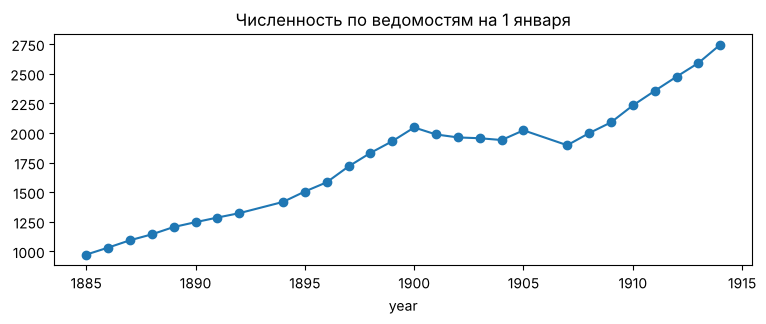

In [12]:
def clean_staff(df):
    df = df.copy()
    df['tab'] = df['tab_no'].map(to_tab)
    df['year'] = df['year'].astype(int)
    df['level'] = df['position'].map(pos_level)
    df['dept'] = df['shop'].map(norm_dept)
    df['salary'] = pd.to_numeric(df['salary_year'], errors='coerce')
    df = df.drop_duplicates(subset=['tab', 'year'])
    return df[['tab', 'year', 'level', 'dept', 'salary']]


staff = clean_staff(staff_raw)
years_present = sorted(staff['year'].unique())
print('годы ведомостей:', years_present[0], '-', years_present[-1], ' отсутствуют:', sorted(set(range(1885, 1915)) - set(years_present)))
staff.groupby('year').size().plot(figsize=(9, 3), title='Численность по ведомостям на 1 января', marker='o');

## 2. Траектории: найм, выход, цензурирование

Для каждого человека нужны год найма, год выхода (или цензурирование) и все повышения и переводы.

Три момента, на которых легко ошибиться:
1. **Левое усечение.** Люди, нанятые до 1885 года, попадают в архив, только если дослужили до 1885 - кто ушёл раньше, в ведомостях не числится. Если считать для них годы службы до 1885 года, получится выборка выживших и риск выхода в первые годы будет занижен. Поэтому годы до 1885 в риск не идут, но стаж считается от настоящего найма.
2. **Правое цензурирование.** Записи после 1913 года есть (около 13%), но фонд за эти годы неполный. Всё, что после 31.12.1913, в модель не попадает, а люди, которые служат на конец 1913 года, цензурированы.
3. **Выходы без записи.** Часть людей пропадает из ведомостей без записи об увольнении. Если их не найти, они будут считаться служащими до 1913 года, и риск выхода занизится. Правило: человек был в ведомости года L, его нет во всех следующих сохранившихся ведомостях, и записей о нём после года L тоже нет - значит, он ушёл в году L. Если человек не попал ни в одну ведомость, он ушёл в год найма, ещё до первого 1 января. Пропуск в одной ведомости при наличии следующих - это ошибка писаря, а не выход. Сюда же попадают записи об увольнении, у которых не прочиталась дата.

In [13]:
def build_people(rec, staff, form):
    g = rec.groupby('tab')
    p = pd.DataFrame(index=form.index)
    hires = rec[rec['type'] == 'hire'].sort_values(['year', 'month', 'day'])
    first_h = hires.drop_duplicates('tab').set_index('tab')
    p['hire_y'] = first_h['year']
    p['level0'] = first_h['level']
    p['dept0'] = first_h['dept']
    # у кого нет даты найма - беру первый год, в котором человек хоть где-то упоминается
    first_any = pd.concat([rec[['tab', 'year']], staff[['tab', 'year']].assign(year=staff['year'] - 1)]).groupby('tab')['year'].min()
    miss = p['hire_y'].isna()
    p.loc[miss, 'hire_y'] = first_any.reindex(p.index[miss])
    print('найм восстановлен по первому упоминанию:', miss.sum())

    ex = rec[(rec['type'] == 'exit')].sort_values('year').drop_duplicates('tab', keep='first').set_index('tab')
    p['exit_y'] = ex['year']
    p['exit_reason'] = ex['reason']
    p['exit_src'] = np.where(p['exit_y'].notna(), 'запись', None)

    # выходы без записи по ведомостям
    last_list = staff.groupby('tab')['year'].max()
    last_rec = rec.groupby('tab')['year'].max()
    LAST_LIST_YEAR = staff['year'].max()   # ведомость на 1.01.1914 показывает, кто дослужил до конца 1913
    cand = p.index[p['exit_y'].isna()]
    # кто ни разу не попал в ведомость, тот ушёл в год найма, до ближайшего 1 января:
    # для них последним годом присутствия считаю год найма
    L = last_list.reindex(cand).fillna(p.loc[cand, 'hire_y'])
    lr = last_rec.reindex(cand)
    silent = L.notna() & (L < LAST_LIST_YEAR) & (lr.isna() | (lr <= L))
    sil_idx = L.index[silent]
    p.loc[sil_idx, 'exit_y'] = L[silent]
    p.loc[sil_idx, 'exit_src'] = 'ведомость'
    print('выходов по записям:', (p['exit_src'] == 'запись').sum(), ' без записи, найдено по ведомостям:', silent.sum())

    p = p.join(form)
    # кого не нанимали в окне и кто ушёл до него - не наша выборка
    p = p[p['hire_y'].notna() & (p['hire_y'] <= OBS_END)]
    p = p[p['exit_y'].isna() | (p['exit_y'] >= OBS_START)]
    # выходы после окна - это цензурирование, а не выход
    p.loc[p['exit_y'] > OBS_END, ['exit_y', 'exit_reason', 'exit_src']] = [np.nan, None, None]
    p['entry_y'] = p['hire_y'].clip(lower=OBS_START)
    p['left_trunc'] = (p['hire_y'] < OBS_START).astype(int)
    return p


people = build_people(rec, staff, form)
print(people.shape, ' нанятых до 1885:', people['left_trunc'].sum(), ' вышли в окне:', people['exit_y'].notna().sum())
people.head()

найм восстановлен по первому упоминанию: 229
выходов по записям: 4581  без записи, найдено по ведомостям: 493
(7251, 13)  нанятых до 1885: 990  вышли в окне: 4475


,hire_y,level0,dept0,exit_y,exit_reason,exit_src,fio,birth_y,birth_approx,estate,edu,entry_y,left_trunc
tab,,,,,,,,,,,,,
3423,1884.0,0.0,паровозный,1885.0,по прошению,запись,Ершов М. Я.,1869.0,0,крестьяне,0.0,1885.0,1
22100,1910.0,0.0,путь,NaN,NaN,NaN,Андреев М. И.,1892.0,1,мещане,1.0,1910.0,0
7833,1893.0,1.0,вагонный,1894.0,не указана,запись,Филатов А. И.,1860.0,0,крестьяне,2.0,1893.0,0
11778,1898.0,0.0,путь,1898.0,по прошению,запись,Назаров А. С.,1871.0,0,NaN,1.0,1898.0,0
6362,1890.0,0.0,вагонный,1892.0,не указана,запись,Денисов А. М.,1874.0,0,мещане,0.0,1890.0,0


In [14]:
# выход раньше найма или рождение после найма - явные ошибки, проверяю что таких нет или почти нет
print('выход раньше найма:', (people['exit_y'] < people['hire_y']).sum())
age_hire = people['hire_y'] - people['birth_y']
print('возраст при найме:', age_hire.describe().round(1).to_dict())
bad = (age_hire < 12) | (age_hire > 60)
print('неправдоподобный возраст при найме:', bad.sum())
people.loc[bad, 'birth_y'] = np.nan

выход раньше найма: 1
возраст при найме: {'count': 6772.0, 'mean': 24.0, 'std': 7.3, 'min': -22.0, '25%': 17.0, '50%': 24.0, '75%': 30.0, 'max': 48.0}
неправдоподобный возраст при найме: 4


In [15]:
people['exit_reason'].value_counts(dropna=False)

exit_reason
NaN                  3114
по прошению          2321
дисциплинарное        829
болезнь               241
смерть                186
сокращение штатов     186
забастовка            171
не указана            143
пенсия                 60
Name: count, dtype: int64

## 3. Человеко-годы

Модель дискретного времени: одна строка - один человек в одном календарном году. Все признаки берутся на 1 января этого года, исход - что случилось за год: выход, повышение или ничего.
Если в одном году было и повышение, и выход, исход - выход (после выхода человек уже не под риском). Год найма тоже идёт в выборку как стаж 0: он неполный, но именно в первые месяцы уходит больше всего людей, и выкинуть его значит потерять главный эффект.

In [16]:
def state_events(rec, people):
    # события, меняющие состояние: найм, повышение, перевод. Сортирую внутри человека по дате,
    # неизвестный месяц ставлю в середину года
    ev = rec[rec['type'].isin(['hire', 'promo', 'transfer']) & rec['tab'].isin(people.index) & rec['year'].notna()].copy()
    ev['mo'] = ev['month'].fillna(6.5)
    ev = ev.sort_values(['tab', 'year', 'mo'])
    return ev


def build_person_years(people, rec, staff):
    ev = state_events(rec, people)
    ev_by = {k: v for k, v in ev.groupby('tab')}
    sal = rec[rec['salary'].notna()].sort_values(['tab', 'year'])
    sal_by = {k: v for k, v in sal.groupby('tab')}
    st_sal = staff.set_index(['tab', 'year'])['salary']
    rows = []
    for tab, p in people.iterrows():
        e = ev_by.get(tab, ev.iloc[:0])
        last = OBS_END if pd.isna(p['exit_y']) else int(p['exit_y'])
        level, dept, lvl_y, n_tr = p['level0'], p['dept0'], p['hire_y'], 0
        ev_list = list(zip(e['year'], e['type'], e['level'], e['dept']))
        s = sal_by.get(tab)
        s_list = list(zip(s['year'], s['salary'])) if s is not None else []
        # оклад при найме известен сразу, его беру для строки года найма
        hire_w = e.loc[e['type'] == 'hire', 'salary'].dropna()
        hire_w = hire_w.iloc[0] if len(hire_w) else np.nan
        i = 0
        j = 0
        wage = np.nan
        for y in range(int(p['hire_y']), last + 1):
            # применяю все события строго до 1 января года y
            while i < len(ev_list) and ev_list[i][0] < y:
                yy, tp, lv, dp = ev_list[i]
                if tp == 'promo' and not pd.isna(lv):
                    level, lvl_y = lv, yy
                elif tp == 'transfer':
                    n_tr += 1
                    if not pd.isna(dp):
                        dept = dp
                elif tp == 'hire':
                    if not pd.isna(lv):
                        level = lv
                    if not pd.isna(dp):
                        dept = dp
                i += 1
            while j < len(s_list) and s_list[j][0] < y:
                wage = s_list[j][1]
                j += 1
            if y < OBS_START:
                continue
            # в ведомости на 1 января оклад записан ровно на нужный момент, она надёжнее последней записи
            w = st_sal.get((tab, y), np.nan)
            if y == int(p['hire_y']):
                w = hire_w
            promo = any(t == 'promo' and yy == y for yy, t, _, _ in ev_list)
            ex = (not pd.isna(p['exit_y'])) and int(p['exit_y']) == y
            rows.append((tab, y, y - int(p['hire_y']), level, dept, y - lvl_y, n_tr,
                         w if not pd.isna(w) else wage, 2 if ex else (1 if promo else 0)))
    py = pd.DataFrame(rows, columns=['tab', 'year', 'tenure', 'level', 'dept', 'yil', 'n_transfers', 'wage', 'y'])
    return py


py = build_person_years(people, rec, staff)
print(py.shape)
print(py['y'].value_counts().rename({0: 'ничего', 1: 'повышение', 2: 'выход'}).to_dict())
py.head()

(56869, 9)
{'ничего': 44831, 'повышение': 7564, 'выход': 4474}


,tab,year,tenure,level,dept,yil,n_transfers,wage,y
0,3423,1885,1,0.0,паровозный,1.0,0,83.0,2
1,22100,1910,0,0.0,путь,0.0,0,174.0,0
2,22100,1911,1,0.0,путь,1.0,0,176.0,0
3,22100,1912,2,0.0,путь,2.0,0,177.0,1
4,22100,1913,3,1.0,путь,1.0,0,267.0,1


In [17]:
# проверка: число выходов в человеко-годах совпадает с числом вышедших в окне
print(py['y'].eq(2).sum(), people['exit_y'].notna().sum())
print('пропуски:', py[['level', 'dept', 'wage']].isna().mean().round(4).to_dict())

4474 4475
пропуски: {'level': 0.0, 'dept': 0.026, 'wage': 0.0122}


## 4. Описательный анализ

### 4.1 Таблица дожития по стажу

Риск выхода h(t) - доля ушедших за год среди тех, кто начал год со стажем t. Дожитие S(t) - произведение (1 - h) по всем годам до t, это дискретный аналог Каплана-Мейера. Цензурированные люди корректно выпадают из знаменателя сами, потому что после 1913 года у них просто нет строк.

In [18]:
def life_table(df, max_t=20):
    d = df.assign(t=df['tenure'].clip(upper=max_t)).groupby('t').agg(at_risk=('y', 'size'), exits=('y', lambda s: (s == 2).sum()))
    d['h'] = d['exits'] / d['at_risk']
    d['S'] = (1 - d['h']).cumprod()
    return d


lt = life_table(py)
print(lt.head(12).round(3))
print('медианный срок службы, лет:', int((lt['S'] < 0.5).idxmax()))

    at_risk  exits      h      S
t                               
0      6260    962  0.154  0.846
1      5076   1037  0.204  0.673
2      3903    524  0.134  0.583
3      3256    261  0.080  0.536
4      2871    208  0.072  0.497
5      2547    136  0.053  0.471
6      2344    118  0.050  0.447
7      2161    109  0.050  0.425
8      1975    109  0.055  0.401
9      1817     54  0.030  0.389
10     1746     64  0.037  0.375
11     1673     50  0.030  0.364
медианный срок службы, лет: 4


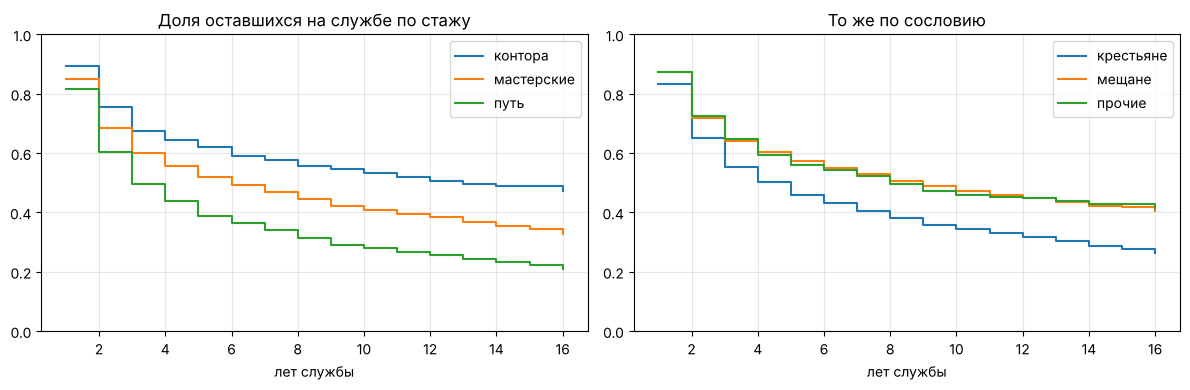

In [19]:
py = py.join(people[['estate', 'edu', 'birth_y', 'left_trunc']], on='tab')
py['track'] = np.where(py['dept'].eq('контора'), 'контора', np.where(py['dept'].eq('путь'), 'путь', 'мастерские'))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, g in py.groupby('track'):
    s = life_table(g, 15)['S']
    ax[0].step(s.index + 1, s.values, where='post', label=name)
for name, g in py.groupby('estate'):
    s = life_table(g, 15)['S']
    ax[1].step(s.index + 1, s.values, where='post', label=name)
ax[0].set_title('Доля оставшихся на службе по стажу')
ax[1].set_title('То же по сословию')
for a in ax:
    a.set_xlabel('лет службы')
    a.set_ylim(0, 1)
    a.grid(alpha=0.3)
    a.legend()
plt.tight_layout()

Самые опасные первые два календарных года: в год найма уходит 15% (год неполный), в следующий ещё 20%, и к 1 января третьего года остаётся только две трети нанятых. Медианный срок службы около 4 лет. Дальше риск падает и с 5-6 лет стажа выходит на плато около 3-5% в год.

Через 5 лет службы в конторе остаётся 62%, в мастерских 52%, в службе пути 39%. Крестьяне уходят чаще мещан (46% против 57% через 5 лет): для рабочих этого времени уход обратно в деревню - обычное дело.

### 4.2 Риск по календарным годам

,exit,promo,n
year,,,
1890,0.067,0.137,1405
1891,0.093,0.127,1478
1899,0.071,0.154,2230
1900,0.097,0.096,2226
1904,0.067,0.140,2178
1905,0.178,0.099,2261
1906,0.109,0.093,2151
1907,0.062,0.134,2154


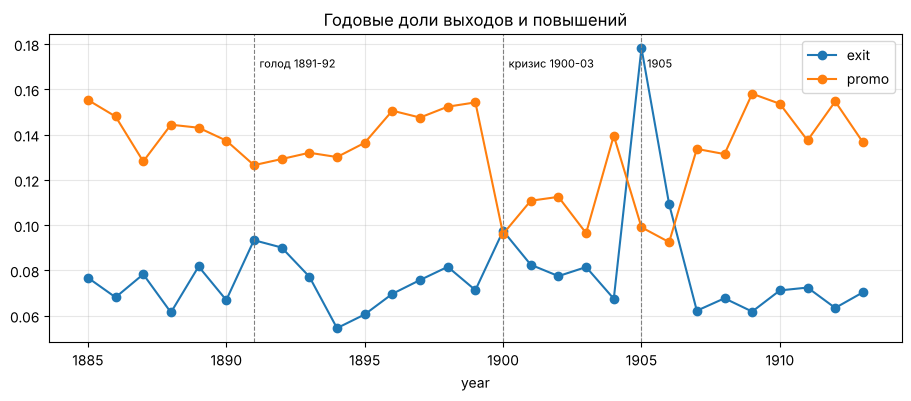

In [20]:
by_year = py.groupby('year').agg(exit=('y', lambda s: (s == 2).mean()), promo=('y', lambda s: (s == 1).mean()), n=('y', 'size'))
ax = by_year[['exit', 'promo']].plot(figsize=(11, 4), marker='o', title='Годовые доли выходов и повышений')
for y0, txt in [(1891, 'голод 1891-92'), (1900, 'кризис 1900-03'), (1905, '1905')]:
    ax.axvline(y0, color='grey', ls='--', lw=0.8)
    ax.text(y0 + 0.2, ax.get_ylim()[1] * 0.92, txt, fontsize=8)
ax.grid(alpha=0.3)
by_year.loc[[1890, 1891, 1899, 1900, 1904, 1905, 1906, 1907]].round(3)

In [21]:
# причины выхода по периодам: в 1905-1906 больше четверти увольнений - за забастовку,
# в кризис 1900-1903 растёт доля сокращений штатов
people['period'] = pd.cut(people['exit_y'], [1884, 1899, 1904, 1906, 1913], labels=['1885-1899', '1900-1904', '1905-1906', '1907-1913'])
pd.crosstab(people['exit_reason'].fillna('без записи'), people['period'], normalize='columns').round(2)

period,1885-1899,1900-1904,1905-1906,1907-1913
exit_reason,,,,
без записи,0.07,0.07,0.10,0.09
болезнь,0.06,0.05,0.03,0.06
дисциплинарное,0.20,0.18,0.14,0.19
забастовка,0.00,0.00,0.27,0.00
не указана,0.04,0.03,0.03,0.03
пенсия,0.01,0.02,0.02,0.02
по прошению,0.56,0.47,0.37,0.56
смерть,0.04,0.04,0.04,0.05
сокращение штатов,0.03,0.15,0.00,0.00


Периоды видны отчётливо. Для модели это проблема: календарный год нельзя дать признаком, потому что при прогнозе на будущие годы его эффект неизвестен. Вместо этого использую то, что известно на 1 января: долю ушедших в организации за прошлый год. Она частично ловит затяжные кризисы (1906 после 1905), но первый год шока предсказать не может в принципе.

### 4.3 Узкие места: сколько лет сидят на одном уровне

То же дожитие, только событие - повышение, а выход считается цензурированием. Медиана - через сколько лет половина людей уровня получает повышение, если не уходит.

In [22]:
def time_in_level(df, level, max_t=15):
    g = df[df['level'] == level]
    d = g.assign(t=g['yil'].clip(upper=max_t)).groupby('t').agg(n=('y', 'size'), promo=('y', lambda s: (s == 1).sum()))
    d['S'] = (1 - d['promo'] / d['n']).cumprod()
    med = d.index[d['S'] < 0.5]
    return (med[0] + 1 if len(med) else np.nan), g.shape[0], (g['y'] == 1).mean(), (g['y'] == 2).mean()


rows = []
for lv in range(5):
    med, n, pr, ex = time_in_level(py, lv)
    rows.append((lv, n, round(pr, 3), round(ex, 3), med))
bottle = pd.DataFrame(rows, columns=['уровень', 'человеко-лет', 'повышений в год', 'выходов в год', 'медиана лет до повышения']).set_index('уровень')
bottle

,человеко-лет,повышений в год,выходов в год,медиана лет до повышения
уровень,,,,
0,8105,0.211,0.185,3.0
1,11351,0.196,0.109,4.0
2,11878,0.162,0.067,5.0
3,10381,0.105,0.039,7.0
4,8236,0.076,0.031,9.0


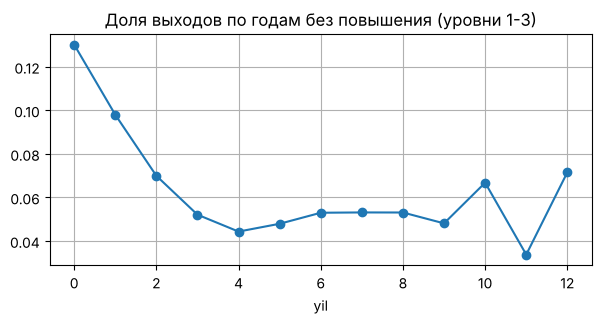

In [23]:
# риск выхода в зависимости от того, сколько лет человек без повышения (уровни 1-3, где застревают)
g = py[py['level'].between(1, 3)]
r = g.assign(yil=g['yil'].clip(upper=12)).groupby('yil')['y'].apply(lambda s: (s == 2).mean())
r.plot(marker='o', figsize=(7, 3), title='Доля выходов по годам без повышения (уровни 1-3)', grid=True);

Самое узкое место - уровни 3 и 4: старший рабочий и помощник мастера ждут следующего повышения в среднем 7 и 9 лет, на нижних уровнях 3-5 лет. Второй график показывает, что после 4 лет без повышения риск выхода перестаёт падать и немного растёт, хотя по общему стажу он должен продолжать снижаться. Это место, где кадровая политика (аттестация, ротация) может что-то изменить.

## 5. Признаки

Всё на 1 января года строки:
- стаж и год найма (стаж 0 - неполный год);
- уровень, служба, сколько лет на уровне, число переводов;
- возраст, образование, сословие (для пропусков отдельные флаги, пропуски не случайные: у старых формуляров чаще нет года рождения);
- относительный оклад - логарифм отношения оклада к медиане по той же службе, уровню и году. Абсолютный оклад смысла не имеет: он растёт с уровнем и с инфляцией после 1897 года, а сравнивать человека надо с теми, кто рядом;
- доля выходов и повышений по всей организации за прошлый год;
- флаг левого усечения (нанят до 1885).

In [24]:
def add_features(py):
    df = py.copy()
    df['age'] = df['year'] - df['birth_y']
    med = df.groupby(['track', 'level', 'year'])['wage'].transform('median')
    df['rel_wage'] = np.log(df['wage'] / med)
    org = df.groupby('year')['y'].agg(lambda s: (s == 2).mean())
    org_p = df.groupby('year')['y'].agg(lambda s: (s == 1).mean())
    # сдвиг на год: в строку года y попадает доля за год y-1, она известна на 1 января
    df['org_exit_prev'] = df['year'].map(org.shift(1))
    df['org_promo_prev'] = df['year'].map(org_p.shift(1))
    return df


df = add_features(py)
print(df[['age', 'rel_wage', 'org_exit_prev']].describe().round(3))

             age   rel_wage  org_exit_prev
count  52854.000  56174.000      55736.000
mean      34.483      0.012          0.079
std       11.826      0.200          0.023
min       14.000     -1.183          0.055
25%       25.000     -0.119          0.067
50%       33.000      0.000          0.072
75%       42.000      0.125          0.082
max       76.000      1.245          0.178


Для логистической регрессии стаж и годы на уровне нелинейны, поэтому разбиваю их на интервалы (по таблице дожития: 0, 1, 2, 3-4, 5-9, 10+), возраст даю кусочно-линейно с изломом в 50 лет. Пропуски заполняю медианой обучающей части и добавляю флаг. Для LightGBM всё отдаю как есть, пропуски он обрабатывает сам.

In [25]:
CAT_DEPT = ['паровозный', 'вагонный', 'кузнечный', 'путь', 'контора']


SHOCKS = {'sh_famine': [1891, 1892], 'sh_crisis': [1900, 1901, 1902, 1903], 'sh_1905': [1905, 1906]}


def design_logit(d, fill, full=True, shocks=None):
    X = pd.DataFrame(index=d.index)
    t = d['tenure']
    for lo, hi in [(1, 1), (2, 2), (3, 4), (5, 9), (10, 99)]:
        X[f'ten_{lo}_{hi}'] = t.between(lo, hi).astype(int)
    for lv in range(1, 6):
        X[f'lvl_{lv}'] = (d['level'] == lv).astype(int)
    for dp in CAT_DEPT[1:]:
        X[f'dept_{dp}'] = (d['dept'] == dp).astype(int)
    if not full:
        return X
    yil = d['yil']
    X['yil'] = yil.clip(upper=15)
    X['yil_over4'] = (yil - 4).clip(lower=0, upper=10)
    X['lvl0_yil'] = (d['level'] == 0) * yil.clip(upper=4)   # у учеников срок обучения работает иначе: повышение почти гарантировано через 2-3 года
    age = d['age'].fillna(fill['age'])
    X['age'] = age
    X['age_over50'] = (age - 50).clip(lower=0)
    X['age_under18'] = (age < 18).astype(int)
    X['age_na'] = d['age'].isna().astype(int)
    X['edu'] = d['edu'].fillna(fill['edu'])
    X['edu_na'] = d['edu'].isna().astype(int)
    X['est_krest'] = (d['estate'] == 'крестьяне').astype(int)
    X['est_proch'] = (d['estate'] == 'прочие').astype(int)
    X['est_na'] = d['estate'].isna().astype(int)
    X['rel_wage'] = d['rel_wage'].fillna(0).clip(-1, 1)
    X['wage_na'] = d['rel_wage'].isna().astype(int)
    X['n_tr'] = d['n_transfers'].clip(upper=3)
    X['org_exit_prev'] = 100 * d['org_exit_prev'].fillna(fill['org_exit_prev'])   # в процентах, чтобы OR читался на 1 п.п.
    X['org_promo_prev'] = 100 * d['org_promo_prev'].fillna(fill['org_promo_prev'])
    X['left_trunc'] = d['left_trunc']
    # шоки: при обучении отмечаю известные кризисные годы, при прогнозе ставлю 0.
    # тогда коэффициенты остальных признаков оцениваются "очищенными" от кризисов, а прогноз означает
    # риск в обычный год. Предсказать сам шок заранее модель всё равно не может
    if shocks == 'train':
        for k, yrs in SHOCKS.items():
            X[k] = d['year'].isin(yrs).astype(int)
    elif shocks == 'zero':
        for k in SHOCKS:
            X[k] = 0
    return X


LGB_COLS = ['tenure', 'level', 'yil', 'age', 'edu', 'rel_wage', 'n_transfers', 'org_exit_prev', 'org_promo_prev', 'left_trunc', 'dept_c', 'estate_c']


def design_lgb(d):
    X = d.copy()
    X['dept_c'] = X['dept'].map({k: i for i, k in enumerate(CAT_DEPT)})
    X['estate_c'] = X['estate'].map({'крестьяне': 0, 'мещане': 1, 'прочие': 2})
    return X[LGB_COLS].astype(float)

## 6. Модели и проверка по периодам

Сравниваю пять моделей, все три исхода (ничего / повышение / выход) предсказываются вместе, как конкурирующие риски:
1. таблица дожития - риск зависит только от стажа (это и есть базовая линия, лучше которой надо быть);
2. мультиномиальная логистическая регрессия на стаже, уровне и службе;
3. та же регрессия на всех признаках - это и есть discrete-time hazard model;
4. она же, но при обучении отмечены известные кризисные годы (голод 1891-92, кризис 1900-03, 1905-06), а при прогнозе эти отметки равны нулю;
5. LightGBM на тех же признаках, что и модель 3.

Валидация только по времени. Случайное разбиение тут нельзя: строки одного человека в соседних годах почти одинаковые и попали бы и в обучение, и в проверку, а модели в реальности всегда придётся предсказывать будущее. Пять фолдов: обучение на всех годах до границы, проверка на трёх следующих (1899-1901, 1902-1904, 1905-1907, 1908-1910, 1911-1913). Модель внутри тестового окна не переобучается, но признаки на 1 января каждого года берутся актуальные - так же модель работала бы на практике, если раз в год пересчитывать риски.

Метрики: ROC-AUC отдельно для выхода и для повышения (насколько хорошо модель ранжирует людей), мультиклассовый log loss и O/E - отношение числа наблюдённых выходов к сумме предсказанных вероятностей. O/E показывает калибровку: 1 значит, что модель в среднем не ошибается в числе ушедших.

In [26]:
def fit_predict(name, tr, te):
    if name == 'life_table':
        t_tr = tr['tenure'].clip(upper=10)
        rates = pd.crosstab(t_tr, tr['y'], normalize='index').reindex(columns=[0, 1, 2], fill_value=0)
        return rates.loc[te['tenure'].clip(upper=10)].values
    if name.startswith('logit'):
        fill = {'age': tr['age'].median(), 'edu': tr['edu'].median(), 'org_exit_prev': tr['org_exit_prev'].mean(), 'org_promo_prev': tr['org_promo_prev'].mean()}
        full = name != 'logit_base'
        sh = name == 'logit_shocks'
        Xtr = design_logit(tr, fill, full, 'train' if sh else None)
        Xte = design_logit(te, fill, full, 'zero' if sh else None)
        sc = StandardScaler().fit(Xtr)
        m = LogisticRegression(C=1.0, max_iter=3000)
        m.fit(sc.transform(Xtr), tr['y'])
        return m.predict_proba(sc.transform(Xte))
    if name == 'lgbm':
        m = lgb.LGBMClassifier(objective='multiclass', n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
        m.fit(design_lgb(tr), tr['y'])
        return m.predict_proba(design_lgb(te))


def scores(te, P):
    return {'auc_exit': roc_auc_score(te['y'] == 2, P[:, 2]),
            'auc_promo': roc_auc_score(te['y'] == 1, P[:, 1]),
            'logloss': log_loss(te['y'], P, labels=[0, 1, 2]),
            'O/E exit': (te['y'] == 2).sum() / P[:, 2].sum()}


FOLDS = [1899, 1902, 1905, 1908, 1911]
MODELS = ['life_table', 'logit_base', 'logit_full', 'logit_shocks', 'lgbm']
res = []
oof = {}
for start in FOLDS:
    tr = df[df['year'] < start]
    te = df[df['year'].between(start, start + 2)]
    for name in MODELS:
        P = fit_predict(name, tr, te)
        res.append({'fold': f'{start}-{start + 2}', 'model': name, **scores(te, P)})
        oof.setdefault(name, []).append(pd.DataFrame(P, index=te.index, columns=['p0', 'p1', 'p2']))
res = pd.DataFrame(res)
summary = res.groupby('model', sort=False)[['auc_exit', 'auc_promo', 'logloss', 'O/E exit']].mean().round(3)
summary

,auc_exit,auc_promo,logloss,O/E exit
model,,,,
life_table,0.685,0.668,0.615,1.114
logit_base,0.700,0.744,0.586,1.119
logit_full,0.729,0.760,0.573,1.017
logit_shocks,0.732,0.761,0.575,1.205
lgbm,0.723,0.761,0.577,1.027


In [27]:
# по фолдам: видно, что именно 1905-1907 выбивается
res.pivot(index='fold', columns='model', values='O/E exit')[MODELS].round(2)

model,life_table,logit_base,logit_full,logit_shocks,lgbm
fold,,,,,
1899-1901,1.16,1.17,1.10,1.19,1.11
1902-1904,1.17,1.16,1.08,1.29,1.27
1905-1907,1.63,1.63,1.34,1.72,1.38
1908-1910,0.79,0.80,0.76,0.87,0.65
1911-1913,0.82,0.84,0.81,0.94,0.74


In [28]:
res.pivot(index='fold', columns='model', values='auc_exit')[MODELS].round(3)

model,life_table,logit_base,logit_full,logit_shocks,lgbm
fold,,,,,
1899-1901,0.693,0.709,0.733,0.730,0.722
1902-1904,0.686,0.695,0.730,0.731,0.728
1905-1907,0.672,0.693,0.716,0.734,0.730
1908-1910,0.698,0.718,0.748,0.749,0.729
1911-1913,0.674,0.686,0.716,0.716,0.706


In [29]:
# O/E отдельно в обычные годы и в годы кризисов. Модель с отметками шоков прогнозирует обычный год,
# поэтому честно сравнивать её калибровку надо в первую очередь на обычных годах
shock_years = sorted(sum(SHOCKS.values(), []))
oe = {}
for name in MODELS:
    o = pd.concat(oof[name]).join(df[['y', 'year']])
    sh = o['year'].isin(shock_years)
    oe[name] = {'обычные годы': (o.loc[~sh, 'y'] == 2).sum() / o.loc[~sh, 'p2'].sum(),
                'кризисные годы': (o.loc[sh, 'y'] == 2).sum() / o.loc[sh, 'p2'].sum()}
pd.DataFrame(oe).round(2)

,life_table,logit_base,logit_full,logit_shocks,lgbm
обычные годы,0.84,0.85,0.80,0.93,0.75
кризисные годы,1.53,1.54,1.37,1.64,1.42


### 6.1 Калибровка

Беру предсказания всех фолдов, режу на 10 групп по предсказанному риску выхода и сравниваю средний предсказанный риск с долей реально ушедших, отдельно для обычных и кризисных лет.

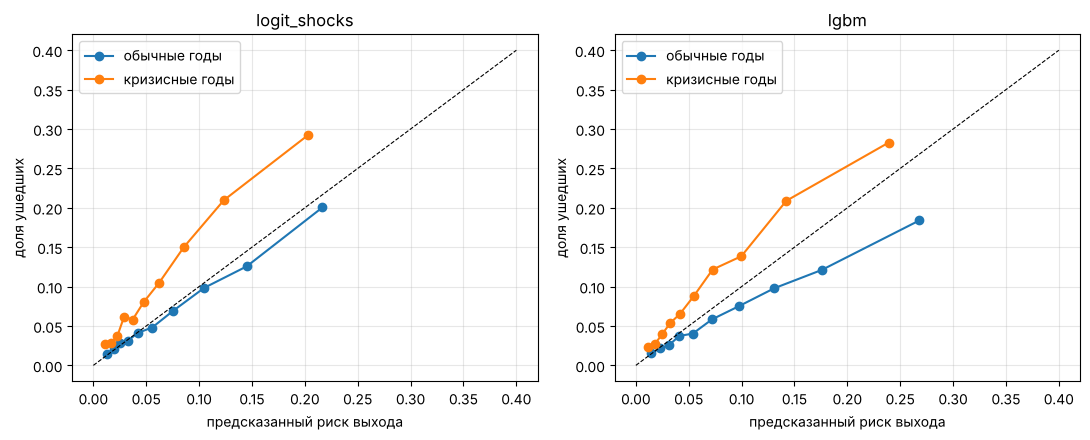

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for k, name in enumerate(['logit_shocks', 'lgbm']):
    o = pd.concat(oof[name]).join(df[['y', 'year']])
    sh = o['year'].isin(shock_years)
    for lab, sub in [('обычные годы', o[~sh]), ('кризисные годы', o[sh])]:
        b = sub.groupby(pd.qcut(sub['p2'], 10, duplicates='drop'), observed=True).agg(pred=('p2', 'mean'), obs=('y', lambda s: (s == 2).mean()))
        ax[k].plot(b['pred'], b['obs'], marker='o', label=lab)
    ax[k].plot([0, 0.4], [0, 0.4], 'k--', lw=0.8)
    ax[k].set_title(name)
    ax[k].set_xlabel('предсказанный риск выхода')
    ax[k].set_ylabel('доля ушедших')
    ax[k].grid(alpha=0.3)
    ax[k].legend()
plt.tight_layout()

Итог по сравнению. Таблица дожития по одному стажу даёт AUC для выхода 0.685, то есть стаж - главный фактор. Уровень и служба добавляют немного (0.700), полный набор признаков - основной прирост (0.729), а для повышений разница ещё больше: 0.668 против 0.760. LightGBM по AUC не лучше регрессии (0.723 и 0.761): зависимости в данных в основном аддитивные, и после ручных интервалов по стажу и изломов по возрасту и годам на уровне регрессии хватает.

Главное различие между моделями в калибровке. Все модели без отметок шоков в обычные годы завышают число выходов (O/E 0.75-0.85), потому что учились на данных, где почти каждый пятый год кризисный, и средний уровень риска у них поднят. Модель с отметками шоков в обычные годы ошибается в числе ушедших на 7% (O/E 0.93), а в кризисные годы, наоборот, занижает выходы в 1.6 раза. Это ожидаемо: шок она и не пытается предсказать, его вклад вынесен в отдельные коэффициенты. По AUC она немного лучше остальных (0.732), её можно читать по коэффициентам и на ней проще делать сценарии, поэтому финальная модель - logit_shocks.

## 7. Финальная модель и интерпретация

Обучаю logit_shocks на всех годах. В мультиномиальной регрессии у каждого класса свои коэффициенты, поэтому эффект признака на риск выхода относительно «ничего не произошло» - это разность коэффициентов класса «выход» и класса «ничего». Перевожу их в отношения шансов на единицу признака (делю на стандартное отклонение из скейлера, потому что регрессия обучалась на стандартизованных признаках).

In [31]:
fill_all = {'age': df['age'].median(), 'edu': df['edu'].median(), 'org_exit_prev': df['org_exit_prev'].mean(), 'org_promo_prev': df['org_promo_prev'].mean()}
X_all = design_logit(df, fill_all, shocks='train')
scaler = StandardScaler().fit(X_all)
final = LogisticRegression(C=1.0, max_iter=3000).fit(scaler.transform(X_all), df['y'])


def predict_final(d):
    # прогноз всегда "на обычный год": отметки шоков нулевые
    return final.predict_proba(scaler.transform(design_logit(d, fill_all, shocks='zero')))


coef = pd.DataFrame(final.coef_.T, index=X_all.columns, columns=['none', 'promo', 'exit'])
odds = pd.DataFrame({'OR выход': np.exp((coef['exit'] - coef['none']) / scaler.scale_),
                     'OR повышение': np.exp((coef['promo'] - coef['none']) / scaler.scale_)}, index=X_all.columns)
odds.round(2)

,OR выход,OR повышение
ten_1_1,1.63,3.97
ten_2_2,1.14,4.00
ten_3_4,0.65,2.62
ten_5_9,0.46,2.58
ten_10_99,0.40,2.93
lvl_1,0.83,1.05
lvl_2,0.58,0.68
lvl_3,0.37,0.34
lvl_4,0.26,0.24
lvl_5,0.21,0.00


In [32]:
# rel_wage - логарифм, поэтому OR на единицу неудобно читать. Пересчитываю на оклад на 10% ниже медианы группы
print('оклад на 10% ниже медианы: шансы выхода x', round(odds.loc['rel_wage', 'OR выход'] ** (-np.log(1.1)), 2))
print('каждый год без повышения после 4-го: шансы выхода x', round(odds.loc['yil', 'OR выход'] * odds.loc['yil_over4', 'OR выход'], 2))

оклад на 10% ниже медианы: шансы выхода x 1.12
каждый год без повышения после 4-го: шансы выхода x 1.08


Как читать (OR - отношение шансов при прочих равных):
- стаж: шансы выхода максимальны на второй календарный год (OR 1.63 относительно года найма, который неполный), к 5-9 годам стажа они в 2-2.5 раза ниже года найма;
- каждый уровень выше снижает риск выхода, у мастера шансы ниже в 5 раз, чем у ученика; служба пути повышает риск на треть относительно паровозного цеха, контора снижает;
- годы без повышения: после 4-го каждый год увеличивает шансы выхода примерно на 8% и уменьшает шансы повышения - это эффект застревания из пункта 4.3;
- относительный оклад: оклад на 10% ниже медианы своей группы даёт +12% к шансам выхода;
- крестьяне уходят чаще (OR 1.41), образование снижает риск выхода и повышает шанс повышения;
- после 50 лет шансы выхода растут на 11% с каждым годом (смерть, болезнь, пенсия);
- кризисы: 1905-1906 годы - OR 3.06 к выходу, голод 1891-92 и кризис 1900-03 - около 1.4. Доля выходов за прошлый год после этого почти ничего не добавляет (OR около 1), вся периодичность ушла в отметки шоков.

Это ассоциации, а не причинные эффекты. Например, оклад зависит от оценки работника начальством, и часть эффекта оклада - это на самом деле эффект того, насколько человек ценный.

## 8. Сценарии

Микросимуляция: беру всех, кто числился на 1 января 1913 года или был нанят в 1913 году, и прогоняю их на 10 лет вперёд по финальной модели в режиме «обычных лет». Каждый год считаю вероятности трёх исходов, разыгрываю исход, обновляю стаж, возраст, уровень и годы на уровне. Доля выходов и повышений в организации за прошлый год фиксирована на среднем по 1907-1913. Каждого человека прогоняю 20 раз, чтобы случайность розыгрыша не влияла на сравнение, а случайные числа во всех сценариях одни и те же.

Сценарии:
1. базовый - всё как есть;
2. надбавка - +10% к окладу на уровнях 0-2 начиная со второго года службы (сдвигается относительный оклад);
3. адресная надбавка - те же +10%, но каждый год только четверти этих людей с самым высоким прогнозом риска выхода;
4. аттестация - если человек 4 года и больше без повышения, шанс повышения за год не меньше 30%. Это политика, а не вывод модели: модель здесь только считает, как изменится риск выхода у тех, кого повысили.

In [33]:
def simulate(base, policy, years=10, reps=20, seed=SEED):
    rng = np.random.default_rng(seed)
    d = pd.concat([base] * reps, ignore_index=True)
    alive = np.ones(len(d), bool)
    out = []
    extra_cost = 0.0
    U = rng.random((years, len(d)))
    for k in range(years):
        cur = d.copy()
        if policy in ('bonus', 'bonus_target'):
            m = ((cur['level'] <= 2) & (cur['tenure'] >= 1)).values
            if policy == 'bonus_target':
                # адресная надбавка: только четверти из тех же людей с самым высоким прогнозом риска выхода
                p_exit = predict_final(cur)[:, 2]
                thr = np.quantile(p_exit[m & alive], 0.75)
                m = m & (p_exit >= thr)
            cur.loc[m, 'rel_wage'] = cur.loc[m, 'rel_wage'].fillna(0) + np.log(1.1)
            extra_cost += 0.1 * cur.loc[m & alive, 'wage_med'].sum() / reps
        P = predict_final(cur)
        if policy == 'review':
            m = ((cur['yil'] >= 4) & (cur['level'] < 5)).values
            need = np.minimum(np.maximum(0.3 - P[:, 1], 0) * m, P[:, 0])
            P[:, 1] += need
            P[:, 0] -= need
        u = U[k]
        ex = alive & (u < P[:, 2])
        pr = alive & ~ex & (u < P[:, 2] + P[:, 1])
        alive &= ~ex
        out.append({'год': k + 1, 'осталось': alive.mean(), 'средний уровень': d.loc[alive, 'level'].mean(), 'повышений': pr.sum() / reps})
        d.loc[pr, 'level'] = (d.loc[pr, 'level'] + 1).clip(upper=5)
        d.loc[pr, 'yil'] = 0
        d.loc[~pr, 'yil'] += 1
        d['tenure'] += 1
        d['age'] += 1
        d['year'] += 1
    return pd.DataFrame(out).set_index('год'), extra_cost


pop = df[df['year'] == 1913].copy()
pop['org_exit_prev'] = df.loc[df['year'].between(1907, 1913), 'y'].eq(2).mean()
pop['org_promo_prev'] = df.loc[df['year'].between(1907, 1913), 'y'].eq(1).mean()
# медианный оклад группы нужен, чтобы посчитать стоимость надбавки в рублях
pop['wage_med'] = pop['wage'] / np.exp(pop['rel_wage'])
pop['wage_med'] = pop['wage_med'].fillna(pop.groupby(['track', 'level'])['wage_med'].transform('median'))
print('человек в симуляции:', len(pop), ' из них 4+ лет без повышения:', ((pop['yil'] >= 4) & (pop['level'] < 5)).sum())

sims = {pol: simulate(pop, pol) for pol in ['base', 'bonus', 'bonus_target', 'review']}
ret = pd.DataFrame({p: s[0]['осталось'] for p, s in sims.items()})
lvl = pd.DataFrame({p: s[0]['средний уровень'] for p, s in sims.items()})
pd.concat({'осталось': ret.loc[[1, 3, 5, 10]], 'средний уровень': lvl.loc[[1, 3, 5, 10]]}, axis=1).round(3)

человек в симуляции: 2986  из них 4+ лет без повышения: 827


осталось                            средний уровень                           
        base  bonus bonus_target review            base  bonus bonus_target review
год                                                                               
1      0.928  0.931        0.929  0.928           2.450  2.445        2.447  2.450
3      0.825  0.834        0.829  0.828           2.839  2.822        2.830  2.917
5      0.759  0.770        0.763  0.766           3.137  3.116        3.127  3.271
10     0.626  0.637        0.630  0.645           3.674  3.651        3.664  3.905

bonus: +287 человеко-лет службы за 10 лет (+1.3%)
bonus_target: +104 человеко-лет службы за 10 лет (+0.5%)
review: +258 человеко-лет службы за 10 лет (+1.1%)
bonus: стоит 211,385 руб. за 10 лет, 737 руб. на один сохранённый человеко-год
bonus_target: стоит 42,150 руб. за 10 лет, 405 руб. на один сохранённый человеко-год
повышений за 10 лет: {'base': 2797, 'bonus': 2847, 'bonus_target': 2817, 'review': 3379}


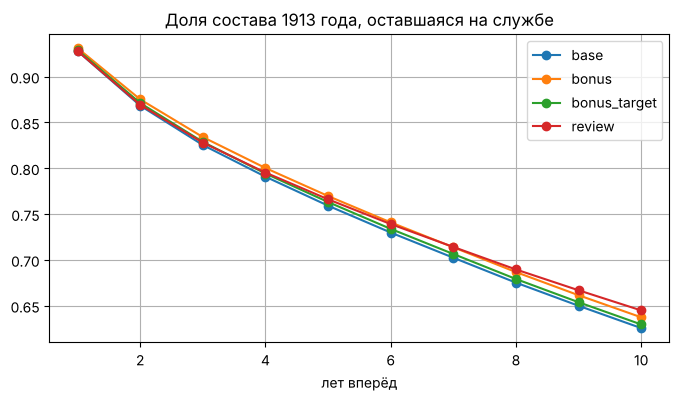

In [34]:
base_py = ret['base'].sum() * len(pop)
for p in ['bonus', 'bonus_target', 'review']:
    gain = (ret[p].sum() - ret['base'].sum()) * len(pop)
    print(f'{p}: +{gain:.0f} человеко-лет службы за 10 лет ({gain / base_py:+.1%})')
for p in ['bonus', 'bonus_target']:
    c = sims[p][1]
    g = (ret[p].sum() - ret['base'].sum()) * len(pop)
    print(f'{p}: стоит {c:,.0f} руб. за 10 лет, {c / g:.0f} руб. на один сохранённый человеко-год')
print('повышений за 10 лет:', {p: round(s[0]['повышений'].sum()) for p, s in sims.items()})

ax = ret.plot(figsize=(8, 4), marker='o', title='Доля состава 1913 года, оставшаяся на службе', grid=True)
ax.set_xlabel('лет вперёд');

Все сценарии дают небольшой эффект, около 1% человеко-лет за 10 лет. Сплошная надбавка действует сразу, но она дорогая: платить приходится всем на нижних уровнях, а удерживает она немногих, поэтому один сохранённый человеко-год стоит около 740 рублей, это примерно два годовых оклада рабочего. Адресная надбавка по прогнозу модели удерживает втрое меньше людей, но обходится в 5 раз дешевле, и сохранённый человеко-год стоит уже около 400 рублей. Аттестация напрямую денег почти не стоит, к 10-му году удерживает чуть больше людей, чем надбавка, и поднимает средний уровень, но требует на 20% больше повышений.

Все оценки скорее сверху. Эффект оклада в модели ассоциативный. А у аттестации есть ограничение, которого модель не видит: число мест мастеров и помощников мастера фиксировано штатным расписанием, и 20% лишних повышений просто некуда деть.